Research Question: Does the risk of an accident decrease linearly with driver experience, or is there a danger zone for young drivers regardless of their years behind the wheel?

In [5]:
# Load in packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay
import seaborn as sns

In [6]:
# Load in dataset
cars = pd.read_csv("/content/dataset_traffic_accident_prediction1.csv")
cars.head()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
0,Rainy,City Road,Morning,1.0,100.0,5.0,0.0,NaN,Wet,Car,51.0,48.0,Artificial Light,0.0
1,Clear,Rural Road,Night,NaN,120.0,3.0,0.0,Moderate,Wet,Truck,49.0,43.0,Artificial Light,0.0
2,Rainy,Highway,Evening,1.0,60.0,4.0,0.0,Low,Icy,Car,54.0,52.0,Artificial Light,0.0
3,Clear,City Road,Afternoon,2.0,60.0,3.0,0.0,Low,Under Construction,Bus,34.0,31.0,Daylight,0.0
4,Rainy,Highway,Morning,1.0,195.0,11.0,0.0,Low,Dry,Car,62.0,55.0,Artificial Light,1.0


In [7]:
# Number of rows and columns in the raw dataset prior to cleaning
cars.shape

(840, 14)

**DATA CLEANING**

In [8]:
# Drop the rows where "Accident" value is missing. The model can't learn the relationship between outcome and features if this is missing.
coches = cars.dropna(subset=['Accident'])

In [9]:
# Removes duplicates. Adresses potential biases of predicting one value over another and prevents potential overfitting.
coches = coches.drop_duplicates()

In [10]:
# Amount of missing values in each column
coches.isna().sum()

,0
Weather,40
Road_Type,40
Time_of_Day,37
Traffic_Density,40
Speed_Limit,41
Number_of_Vehicles,38
Driver_Alcohol,40
Accident_Severity,41
Road_Condition,41
Vehicle_Type,39


In [11]:
# Impute the median for the numeric columns and the mode for the categorical columns
coches = coches.fillna(coches.median(numeric_only=True))
coches = coches.fillna(coches.mode().iloc[0])

In [12]:
# Experience can't logically be greater than age so these instances were set to be equal to each other (about 35 instances)
coches['Driver_Experience'] = coches[['Driver_Experience', 'Driver_Age']].min(axis=1)

In [13]:
# Address data leakage by dropping severity, and then separate the target and feature variables.
X = coches.drop(columns=['Accident', 'Accident_Severity'])
y = coches['Accident']

In [14]:
# Make the categorical variables into dummy variables
X = pd.get_dummies(X, drop_first=True)

In [15]:
# Split the dataset into training and testing datasets using a 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21)

In [16]:
# Scale the numeric values so the model understands sample impact and not size
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**DATA VISUALIZATIONS**

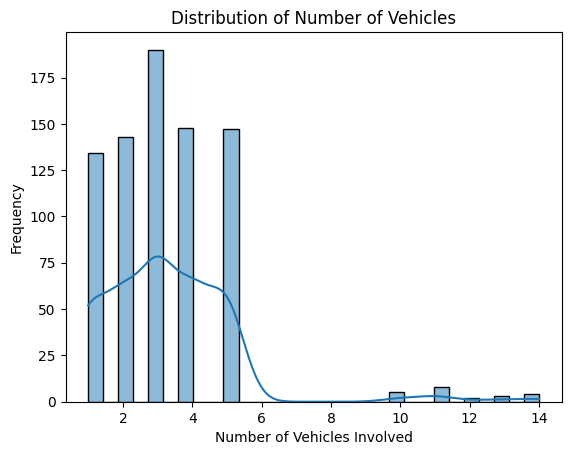

In [50]:
# Plot 1 - visualizing the distributions of the numeric variables
sns.histplot(coches['Number_of_Vehicles'].dropna(), kde=True)

plt.title(f'Distribution of Number of Vehicles')
plt.xlabel('Number of Vehicles Involved')
plt.ylabel('Frequency')
plt.show()

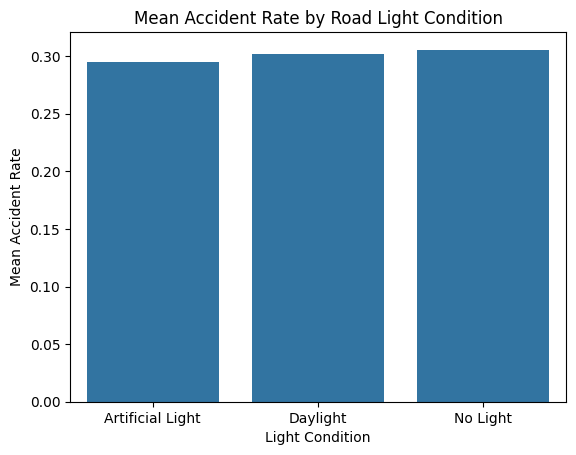

In [56]:
# Plot 2 - average number of accidents based on light conditions (environmental differences)
sns.barplot(data=coches, x='Road_Light_Condition', y='Accident', errorbar=None)

plt.title('Mean Accident Rate by Road Light Condition')
plt.xlabel('Light Condition')
plt.ylabel('Mean Accident Rate')
plt.show()

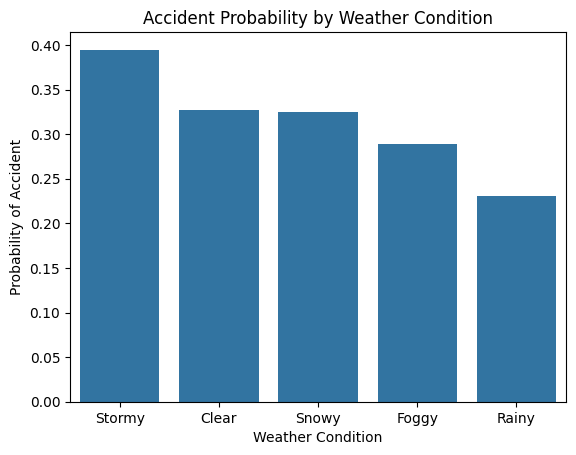

In [61]:
# Plot 3 - what is the probability of getting into an accident given weather conditions
order = coches.groupby('Weather')['Accident'].mean().sort_values(ascending=False).index

sns.barplot(data=coches, x='Weather', y='Accident', order=order, errorbar=None)

plt.title('Accident Probability by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Probability of Accident')
plt.show()

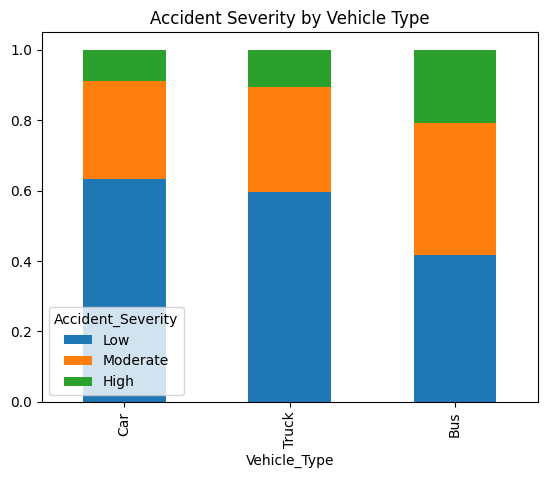

In [60]:
# Plot 4 - severity of crash by vehicle type (also explains what the data representation)
pd.crosstab(
    coches['Vehicle_Type'],
    coches['Accident_Severity'],
    normalize='index'
).loc[['Car', 'Truck', 'Bus'], ['Low', 'Moderate', 'High']] \
 .plot(kind='bar', stacked=True)

plt.title('Accident Severity by Vehicle Type')
plt.show()


**DATA MODELING**

In [18]:
# Model 1 - Simple logit
X_simple = coches[['Driver_Age', 'Driver_Experience']]
X_simple = sm.add_constant(X_simple)
y = coches['Accident']

simple_mod = sm.Logit(y, X_simple).fit()
print(simple_mod.summary())

Optimization terminated successfully.
         Current function value: 0.609377
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:               Accident   No. Observations:                  784
Model:                          Logit   Df Residuals:                      781
Method:                           MLE   Df Model:                            2
Date:                Thu, 23 Apr 2026   Pseudo R-squ.:               0.0003034
Time:                        16:53:29   Log-Likelihood:                -477.75
converged:                       True   LL-Null:                       -477.90
Covariance Type:            nonrobust   LLR p-value:                    0.8650
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.9814      0.250     -3.928      0.000      -1.471      -0.492
Driver_A

In [19]:
# Model 2 - Random Forest -- increased trees from 100 to 1000
rf = RandomForestClassifier(n_estimators=1000, random_state=42)
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(n_estimators=1000, random_state=42)

In [20]:
# Model 3 - Decision tree
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [21]:
# Model 4 - Neural Network
mlp = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42)
mlp.fit(X_train_scaled, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42)

In [22]:
# Model 5 - SVM
svm = SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)

SVC(class_weight='balanced', probability=True, random_state=42)

In [23]:
# Model 6 - Gradient Boosting
gbc = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gbc.fit(X_train_scaled, y_train)

GradientBoostingClassifier(random_state=42)

In [24]:
# Model Accuracy Comparison
decision_acc  = accuracy_score(y_test, dt.predict(X_test_scaled))
random_acc = accuracy_score(y_test, rf.predict(X_test_scaled))
neural_acc = accuracy_score(y_test, mlp.predict(X_test_scaled))
gradient_acc = accuracy_score(y_test, gbc.predict(X_test_scaled))
svm_acc = accuracy_score(y_test, svm.predict(X_test_scaled))

print(f"Decision Tree: {round(decision_acc, 3)}, "
      f"Random Forest: {round(random_acc, 3)}, "
      f"Neural Network: {round(neural_acc, 3)}, "
      f"Gradient Boosting: {round(gradient_acc, 3)}, "
      f"SVM: {round(svm_acc, 3)}")

Decision Tree: 0.682, Random Forest: 0.713, Neural Network: 0.573, Gradient Boosting: 0.656, SVM: 0.535


In [25]:
# Find other performance metric my model - Precision, Recall, F1
trained_models = {
    "Decision Tree": dt,
    "Random Forest": rf,
    "Neural Network": mlp,
    "SVM": svm,
    "Gradient Boosting": gbc
}

performance_metrics = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    performance_metrics.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

performance_df = pd.DataFrame(performance_metrics)
print(performance_df.to_string(index=False))

            Model  Precision   Recall  F1-Score
    Decision Tree   0.200000 0.021277  0.038462
    Random Forest   0.666667 0.085106  0.150943
   Neural Network   0.300000 0.319149  0.309278
              SVM   0.314286 0.468085  0.376068
Gradient Boosting   0.315789 0.127660  0.181818


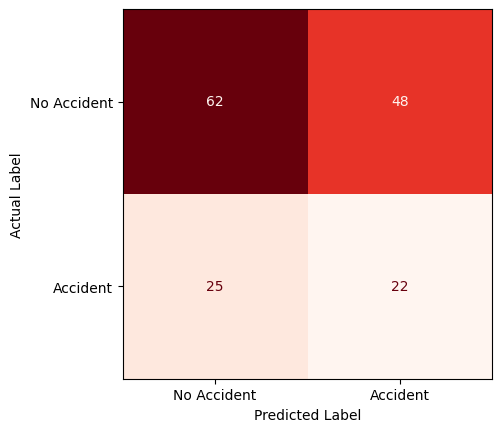

In [26]:
# Create a confusion matrix to visualize the results
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, svm.predict(X_test_scaled),
    display_labels=['No Accident', 'Accident'],
    cmap='Reds', colorbar=False
)

disp.ax_.set(xlabel='Predicted Label', ylabel='Actual Label')
plt.grid(False)
plt.show()

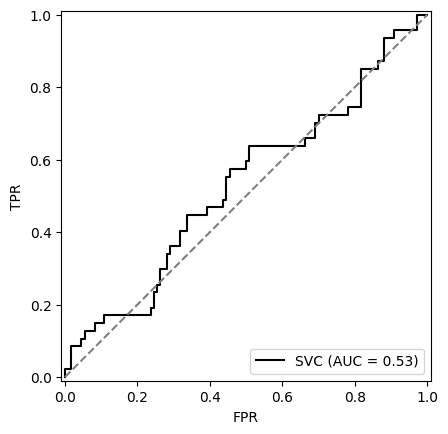

In [28]:
# Additional visual to see classifier performance
disp = RocCurveDisplay.from_estimator(svm, X_test_scaled, y_test, color='black')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
disp.ax_.set(xlabel='FPR', ylabel='TPR')
plt.show()